In [2]:
%load_ext autoreload
%autoreload 2

%matplotlib widget
import json
import os
import pickle as pkl
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import clear_output
from loguru import logger
from tqdm.notebook import tqdm

from prl.classification import lesion_analysis as lesion_dx
from prl.core.dataset import Dataset
from prl.core.experiment import Experiment
from prl.core.inference import uncrop_predictions
from prl.helpers.parallel import BetterPool
from prl.helpers.shell_interface import open_itksnap_workspace_cmd
from prl.helpers.utils import dice_score, get_prl_indices, cached
from prl.scripts.compile_run_metrics import EXPERIMENT_KEYS, load_or_cache_run


In [3]:
def get_infer_path(dataset, test_case, experiment_name) -> Path:
    case_dir = dataset.lesion_dir(test_case)
    matches = list(case_dir.glob(f"*{experiment_name.replace('/','_')}.nii.gz"))
    if len(matches) > 1:
        logger.warning(f"Found more than 1 case: {','.join(matches)}, returning the first")
    return matches[0]

    
def find_inference(search_path, experiment_name) -> Path:
    matches = list(search_path.glob(f"*{experiment_name.replace('/','_')}.nii.gz"))
    if len(matches) > 1:
        logger.warning(f"Found more than 1 case: {','.join(matches)}, returning the first")
    return matches[0]

In [4]:
dataset_name = "roi_train2"
dataset = Dataset(dataset_name)

experiment_key, run_name = "stage6", "run1"
experiment_name = f"{EXPERIMENT_KEYS[experiment_key]}/{run_name}"
# experiment_name = "sweep_dicecewts/run1"
# experiment_name = "test_dicece_lambda/run1"
experiment = Experiment.from_run_dir(experiment_name, dataset)

expand_xy: int = experiment.preprocess_config.expand_xy
expand_z: int = experiment.preprocess_config.expand_z
expand_str = f"xy{expand_xy}_z{expand_z}"
images: tuple[str, ...] = experiment.preprocess_config.images

experiment.show_input_config()

╭──────────────────────────────────── roi_train2/stage6_sweep_dicece_wts/run1 ────────────────────────────────────╮
│                                                                                                                 │
│  input.yaml                                                                                                     │
│  ├── modality: MRI                                                                                              │
│  ├── datalist:                                                                                                  │
│  │   /media/smbshare/srs-9/prl_project/training/roi_train2/stage6_sweep_dicece_wts/run1/datalist_flair.phase_x  │
│  │   y20_z2.json                                                                                                │
│  ├── dataroot: /media/smbshare/srs-9/prl_project/data                                                           │
│  ├── learning_rate: 0.0002                                                                                      │
│  ├── num_epochs: 500                                                                                            │
│  ├── num_images_per_batch: 1                                                                                    │
│  ├── batch_size: 1                                                                                              │
│  ├── num_warmup_epochs: 1                                                                                       │
│  ├── num_epochs_per_validation: 1                                                                               │
│  ├── num_epochs_per_saving: 1                                                                                   │
│  ├── num_crops_per_image: 1                                                                                     │
│  ├── num_workers: 4                                                                                             │
│  ├── roi_size: [44, 44, 8]                                                                                      │
│  ├── crop_mode: ratio                                                                                           │
│  ├── crop_foreground: True                                                                                      │
│  ├── auto_scale_allowed: False                                                                                  │
│  ├── auto_scale_batch: False                                                                                    │
│  ├── auto_scale_roi: False                                                                                      │
│  ├── auto_scale_filters: False                                                                                  │
│  ├── amp: True                                                                                                  │
│  ├── channels_last: True                                                                                        │
│  ├── determ: False                                                                                              │
│  ├── early_stopping_fraction: 0.001                                                                             │
│  └── loss                                                                                                       │
│      ├── _target_: DiceCELoss                                                                                   │
│      ├── include_background: True                                                                               │
│      ├── weight: $torch.tensor([1.0, 1.0, 10.0]).cuda()                                                         │
│      ├── squared_pred: True                                                                                     │
│      ├── smooth_nr: 0                                                                                           │
│      ├── smooth_dr: 1e-05                             

In [5]:
REBUILD = False
cache = Path("cache") / f"inference_{experiment.id}.pkl"

def find_all_inference(cases, experiment_name):
    return pd.Series(
        [find_inference(Path(c.subject_dir) / str(c.name[1]), experiment_name)
         for _, c in tqdm(cases.iterrows(), total=len(cases))],
        index=cases.index,
    ) 

def find_all_labels(cases):
    return pd.Series(
        [c.label if os.path.exists(c.label) else c.subject_dir/str(c.name[1])/f"lesion_{expand_str}.nii.gz"
         for _, c in tqdm(cases.iterrows(), total=len(cases))],
         index=cases.index
    )

inference_dataset = Dataset("inference_dataset")
cases = inference_dataset.cases
cases['inference'] = cached(cache, find_all_inference, cases, experiment_name)
# cases['label'] = find_all_labels(cases)

In [6]:
def analyze_wrapper(args):
    dataset, subid, lesion_indices = args
    return lesion_dx.analyze_subject_prl(subid, dataset, "inference", lesion_indices=lesion_indices)

analysis_dir = Path("/home/srs-9/Projects/prl_project/analysis/")
savepath = analysis_dir/ f"prl_image_stats-{experiment.id.replace('/', '_')}.csv"
if not savepath.exists():
    full_data = defaultdict(list)
    tasks = []
    for subid, g in inference_dataset.cases.reset_index().groupby("subid"):
        tasks.append((inference_dataset, subid, g['lesion_index'].to_list()))
    with BetterPool(8) as pool:
        results_iterator = pool.imap_unordered(analyze_wrapper, tasks)
        for result in tqdm(results_iterator, total=len(tasks)):
            full_data['prl_stats'].extend(result[0])
            full_data['prl_data'].extend(result[1])

    feature_df = pd.DataFrame(full_data['prl_stats'])

    feature_df.to_csv(
        savepath,
        index=False
    )
else:
    feature_df = pd.read_csv(savepath)

feature_df = feature_df.rename(columns={c: f"my_features_{c}" for c in feature_df.columns if c not in ["subid", "lesion_index", "case_type", "has_iron_infer"]})


In [7]:
import subprocess

REBUILD = False
WORKER_SCRIPT = "/home/srs-9/Projects/prl_project/notebooks/radiomics_worker.py"
PYTHON_36 = "/home/srs-9/anaconda3/envs/pyradiomics2/bin/python"
inference_dataset.cases['has_iron'] = feature_df.set_index(["subid", "lesion_index"]).has_iron_infer

svname = f"{experiment.id.replace('/', '-')}-inference_pyradiomics.csv"
savepath = f"/home/srs-9/Projects/prl_project/notebooks/tmp/{svname}"
if not os.path.exists(savepath) or REBUILD:
    # inference_dataset.cases = cases
    # cases = inference_dataset.cases[feature_df.set_index(["subid", "lesion_index"]).has_iron_infer]
    cases = inference_dataset.cases
    cases.groupby("subid")["has_iron"].sum()

    params_rim = "/home/srs-9/Projects/prl_project/notebooks/tmp/radiomics_params_rim.yaml"
    params_lesion = "/home/srs-9/Projects/prl_project/notebooks/tmp/radiomics_params_lesion.yaml"

    all_features = []
    for i in tqdm(range(len(cases))):
        lesion_case = cases.iloc[i]
        subid = lesion_case.name[0]
        lesion_index = lesion_case.name[1]
        lesion_dir = Path(lesion_case['image']).parent
        expand_suffix = f"_xy{inference_dataset.preprocess.expand_xy}_z{inference_dataset.preprocess.expand_z}"
        phase_path = lesion_dir / f"phase{expand_suffix}.nii.gz"
        inference_path = lesion_case['inference']
        gt_label_path = lesion_case['label']

        features = {}
        features['subid'] = subid
        features['lesion_index'] = lesion_index
        for params_label_key, params in [("rim", params_rim), ("lesion", params_lesion), ("lesion_infer", params_lesion)]: 
            if params_label_key in ["rim", "lesion_infer"]:
                mask_path = inference_path
            else:
                mask_path = gt_label_path
            input_data = {"image_path": str(phase_path), "mask_path": str(mask_path), "params": str(params)}
            with open("temp_in.json", "w") as f:
                json.dump(input_data, f)

            try:
                process = subprocess.run(
                    [PYTHON_36, WORKER_SCRIPT, "temp_in.json", "temp_out.json"],
                    capture_output=True,
                    check=True,
                    text=True,
                )
            except subprocess.CalledProcessError as e:
                print(e.stdout)
                print(subid, lesion_index, mask_path)
                print(e.stderr)
                continue

            with open("temp_out.json", 'r') as f:
                tmp_features = json.load(f)

            features.update({
                f"{params_label_key}_{k}": v for k,v in tmp_features.items()
            })
            
        all_features.append(features)
        
        
    all_features_df = pd.DataFrame(all_features)
    all_features_df = all_features_df.set_index(["subid", "lesion_index"])
    all_features_df.to_csv(savepath)
else:
    all_features_df = pd.read_csv(f"/home/srs-9/Projects/prl_project/notebooks/tmp/{svname}")

all_features_df = all_features_df.rename(columns={c: f"pyradiomics_{c}" for c in all_features_df.columns if c not in ["subid", "lesion_index", "case_type", "has_iron_infer"]})

In [8]:
df = inference_dataset.cases.reset_index().merge(
    feature_df,
    on=["subid", "lesion_index"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_y")
)

df = df.merge(
    all_features_df,
    on=["subid", "lesion_index"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_y")
)

df.to_csv(f"{experiment.id.replace('/', '-')}-features_df.csv")

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    auc,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
    precision_recall_curve
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from prl.helpers import assign_prl_folds
from scipy.special import expit


RANDOM_STATE = SEED = 42


classifiers = {
    "LR": LogisticRegression(class_weight="balanced", max_iter=2000),
    "RF": RandomForestClassifier(n_estimators=250, min_samples_leaf=3,
                                    class_weight="balanced", random_state=SEED, n_jobs=-1),
    "SVM": SVC(kernel="rbf", class_weight="balanced"),
}

# %% Configuration

TARGET = "case_type"
POS_LABEL = "PRL"
SCREEN_COL = "has_iron_infer"
SUBJECT_COL = "subid"
LESION_IDX_COL = "lesion_index"
RESULTS_COLS = [
    TARGET,
    SCREEN_COL,
    "fold"
]

TEST_SIZE = 0.10

CLF = "LR"

df = pd.read_csv(f"{experiment.id.replace('/', '-')}-features_df.csv")
data = df.loc[df["case_type"].isin(["PRL", "Lesion"])].copy()
data["fold"] = assign_prl_folds(data, n_splits=5)


# Inspect the achieved balance.
summary = (
    data.assign(is_prl=data["case_type"].eq("PRL"))
    .groupby("fold")
    .agg(
        subjects=("subid", "nunique"),
        lesions=("lesion_index", "size"),
        prls=("is_prl", "sum"),
        prl_prevalence=("is_prl", "mean"),
    )
)
print(summary.round(3))

assert data.groupby("subid")["fold"].nunique().eq(1).all()

data = data.set_index(["subid", "lesion_index"])

# Only evaluate lesions with a known ground-truth class.
data = data.loc[data[TARGET].isin(["PRL", "Lesion"])].copy()

data["y_true"] = data[TARGET].eq(POS_LABEL).astype(int)
data[SCREEN_COL] = data[SCREEN_COL].fillna(False).astype(bool)

FEATURES = [
    "my_features_rim_volume_infer",
    "my_features_rim_hull_volume_infer",
    "my_features_rim_sphere_radius_infer",
    "my_features_pca_size",
    "my_features_pca_sphericity",
    "my_features_pca_planarity",
    "my_features_pca_linearity",
    "my_features_mean_radius",
    "my_features_std_radius",
    "my_features_min_radius",
    "my_features_max_radius",
    "my_features_radial_cv",
]

      subjects  lesions  prls  prl_prevalence
fold                                         
1            9      841    23           0.027
2           10      504    24           0.048
3           11      874    23           0.026
4           11      827    23           0.028
5           11      866    23           0.027


In [10]:
results_df = data[[TARGET, SCREEN_COL, "fold"]].copy()
results_df["y_true"] = data["y_true"].copy()  # Move outside loop
results_df["score"] = 0.0                     # Move outside loop

TN, FP, FN, TP = confusion_matrix(results_df["y_true"], results_df['score']).ravel()
print(TN, FP, FN, TP)

results

3796 0 116 0


NameError: name 'results' is not defined

In [11]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
    ("clf", classifiers[CLF]),
])

results_df = data[[TARGET, SCREEN_COL, "fold"]].copy()
results_df["y_true"] = data["y_true"].copy()  # Move outside loop
results_df["score"] = 0.0                     # Move outside loop

for fold, test_df in data.groupby("fold"):
    # Stage 2 sees only screen-positive lesions from training subjects.
    X_train = data.loc[data["fold"].ne(fold) & data[SCREEN_COL]]
    model.fit(X_train[FEATURES], X_train["y_true"])

    X_test = test_df.loc[test_df[SCREEN_COL], FEATURES]
    if X_test.empty:
        continue

    if CLF == "SVM":
        # Map SVC margins to positive ranking scores above screen rejects.
        # These scores are not calibrated probabilities.
        scores = expit(model.decision_function(X_test))
    else:
        scores = model.predict_proba(X_test)[:, 1]

    results_df.loc[X_test.index, "score"] = scores


In [12]:
fpr, tpr, thresholds = roc_curve(results_df['y_true'], results_df['score'])

j_scores = tpr - fpr
best_idx = np.argmax(j_scores)

best_threshold = thresholds[best_idx]
best_j = j_scores[best_idx]
best_threshold
best_j

np.float64(0.8704898077831473)

In [21]:
fpr, tpr, thresholds = roc_curve(
    results_df["y_true"],
    results_df["score"],
    drop_intermediate=False,
)

# Screen-negative lesions have score 0 and must stay negative.
eligible = np.isfinite(thresholds) & (thresholds > 0)
fpr, tpr, thresholds = fpr[eligible], tpr[eligible], thresholds[eligible]

j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
best_threshold = thresholds[best_idx]

print(f"Threshold:   {best_threshold:.4f}")
print(f"Youden's J:  {j_scores[best_idx]:.3f}")
print(f"Sensitivity: {tpr[best_idx]:.1%}")
print(f"Specificity: {1 - fpr[best_idx]:.1%}")

results_df["pred_prl"] = (
    results_df[SCREEN_COL] & results_df["score"].ge(best_threshold)
)
best_threshold

Threshold:   0.0189
Youden's J:  0.870
Sensitivity: 95.7%
Specificity: 91.4%


np.float64(0.01886290071277416)

In [22]:
j_scores

array([0.00862069, 0.01724138, 0.02586207, 0.03448276, 0.04310345,
       0.04284001, 0.0514607 , 0.06008139, 0.06870208, 0.07732277,
       0.08594346, 0.09456415, 0.09430072, 0.10292141, 0.1115421 ,
       0.12016278, 0.11989935, 0.12852004, 0.13714073, 0.13687729,
       0.14549798, 0.15411867, 0.16273936, 0.17136005, 0.17998074,
       0.17971731, 0.188338  , 0.18807456, 0.18781113, 0.19643182,
       0.20505251, 0.2136732 , 0.21340976, 0.21314632, 0.22176701,
       0.2303877 , 0.23900839, 0.24762908, 0.24736565, 0.25598634,
       0.2557229 , 0.25545947, 0.26408016, 0.27270085, 0.28132154,
       0.2810581 , 0.28079467, 0.28053123, 0.2802678 , 0.28888849,
       0.29750917, 0.30612986, 0.31475055, 0.32337124, 0.33199193,
       0.34061262, 0.34034919, 0.34896988, 0.35759057, 0.35732713,
       0.36594782, 0.37456851, 0.37430508, 0.38292577, 0.39154646,
       0.40016715, 0.40878783, 0.41740852, 0.42602921, 0.42576578,
       0.43438647, 0.44300716, 0.45162785, 0.45136441, 0.45998

In [14]:
cand = results_df.loc[results_df[SCREEN_COL]]
y = results_df["y_true"]
n_pos = int(cand["y_true"].sum())
n_neg = len(cand) - n_pos

# One row per attainable candidate cutoff; tied scores enter together.
sweep = (
    cand.groupby("score")["y_true"]
    .agg(tp="sum", total="size")
    .sort_index(ascending=False)
    .cumsum()
)
sweep["fp"] = sweep["total"] - sweep["tp"]
sweep["J_conditional"] = sweep["tp"] / n_pos - sweep["fp"] / n_neg
sweep["J_full"] = sweep["tp"] / y.sum() - sweep["fp"] / (len(y) - y.sum())

# A descending index makes idxmax choose the highest cutoff in an exact tie.
print(sweep[["J_conditional", "J_full"]].idxmax())

J_conditional    0.483699
J_full           0.018863
dtype: float64


In [25]:
sweep["J_full"].sort_values()

score
0.999941    0.008621
0.999940    0.017241
0.990202    0.025862
0.988734    0.034483
0.984011    0.042840
              ...   
0.038206    0.863186
0.018863    0.869700
0.018863    0.869963
0.018863    0.870226
0.018863    0.870490
Name: J_full, Length: 439, dtype: float64

In [17]:
(
    cand.groupby("score")["y_true"]
    .agg(tp="sum", total="size")
    .sort_index(ascending=False)
    .cumsum()
)

,tp,total
score,,
0.999941,1,1
0.999940,2,2
0.990202,3,3
0.988734,4,4
0.985892,5,5
...,...,...
0.019579,110,438
0.018863,111,439
0.018863,111,440


In [20]:
(cand.groupby("score")["y_true"]
    .agg(tp="sum", total="size")
)

,tp,total
score,,
0.018863,0,1
0.018863,0,1
0.018863,0,1
0.018863,1,1
0.019579,0,1
...,...,...
0.985892,1,1
0.988734,1,1
0.990202,1,1


                        Lesions  PRLs  ROC AUC     AP
Evaluation                                           
Conditional classifier      442   111    0.849  0.674
Full pipeline              3912   116    0.964  0.646


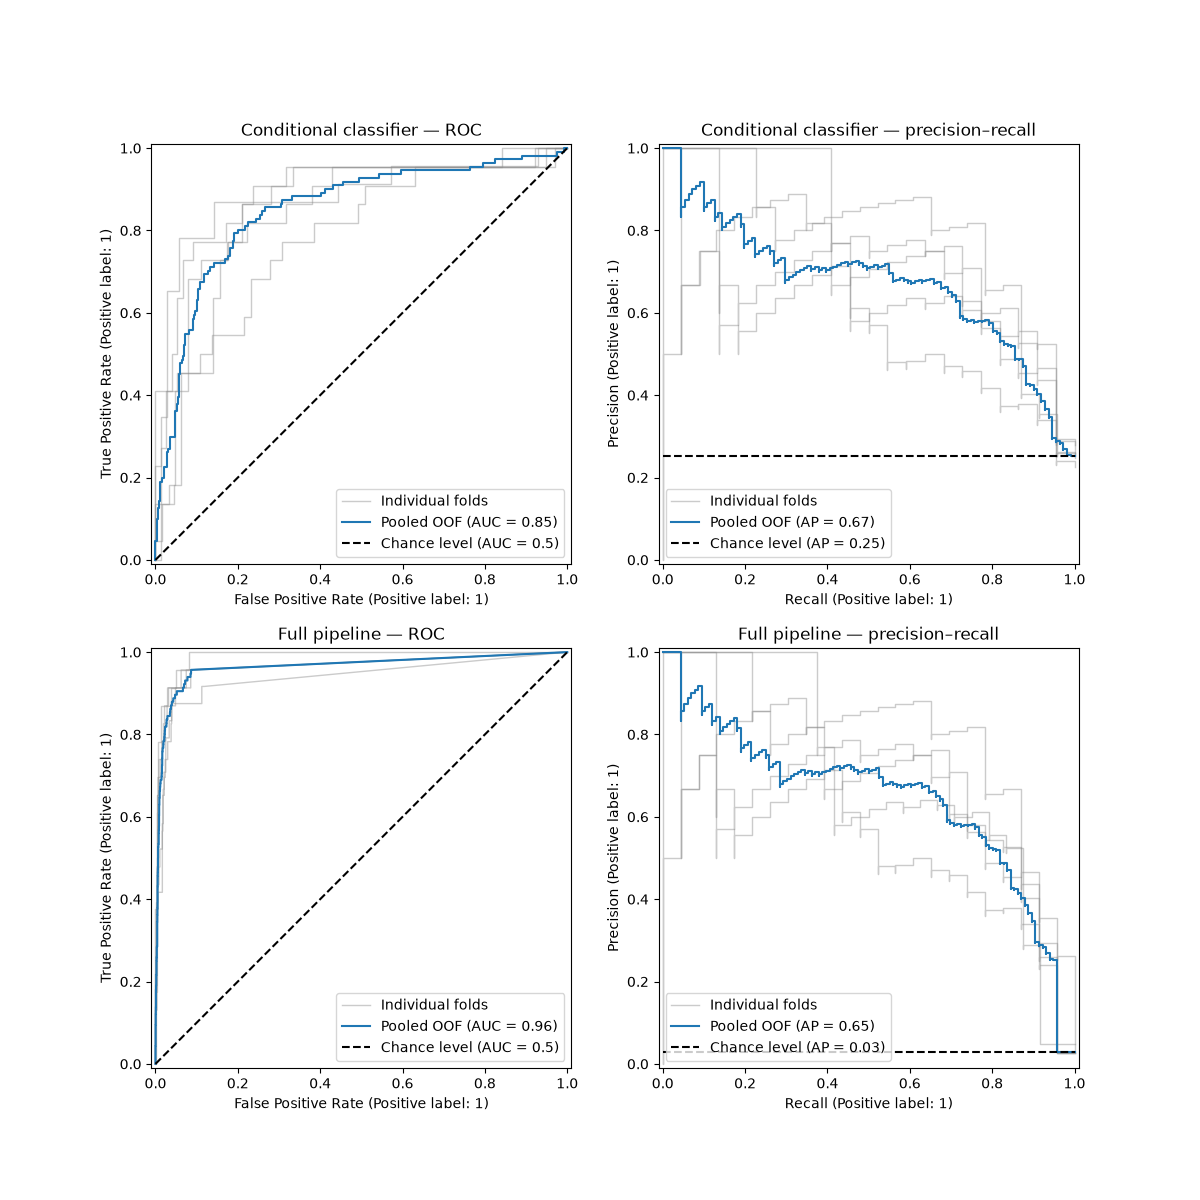

In [19]:
ax_names = [
    ["Conditional ROC", "Conditional PR"],
    ["Pipeline ROC", "Pipeline PR"]
]
fig, ax_grid = plt.subplot_mosaic(ax_names, figsize=(12,12))


rows = []
for (name, frame), (roc_ax_name, pr_ax_name) in zip(
    [
        ("Conditional classifier", results_df[results_df[SCREEN_COL]]),
        ("Full pipeline", results_df)
    ], 
    ax_names
):
    roc_ax = ax_grid[roc_ax_name]
    pr_ax = ax_grid[pr_ax_name]
    for fold, subset in frame.groupby("fold"):
        style = {"color": "0.55", "alpha": 0.45, "lw": 1,
                 "label": "Individual folds" if fold == 1 else "_nolegend_"}
        RocCurveDisplay.from_predictions(subset.y_true, subset.score, ax=roc_ax, curve_kwargs=style)
        PrecisionRecallDisplay.from_predictions(subset.y_true, subset.score, ax=pr_ax, curve_kwargs=style)
    RocCurveDisplay.from_predictions(frame.y_true, frame.score, ax=roc_ax,
                                     name="Pooled OOF", plot_chance_level=True)
    PrecisionRecallDisplay.from_predictions(frame.y_true, frame.score, ax=pr_ax,
                                            name="Pooled OOF", plot_chance_level=True)
    roc_ax.set_title(f"{name} — ROC")
    pr_ax.set_title(f"{name} — precision–recall")
    rows.append({"Evaluation": name, "Lesions": len(frame), "PRLs": frame.y_true.sum(),
                 "ROC AUC": roc_auc_score(frame.y_true, frame.score),
                 "AP": average_precision_score(frame.y_true, frame.score)})
metrics = pd.DataFrame(rows).set_index("Evaluation")
print(metrics.round(3))
plt.show()


In [ ]:
import math

TARGET_SENSITIVITY = 0.80


def threshold_at_sensitivity(frame, target=TARGET_SENSITIVITY):
    """Find the highest cutoff achieving the target full-pipeline sensitivity."""

    positive = frame["y_true"].eq(1)
    passed = frame[SCREEN_COL]
    n_prl = int(positive.sum())
    if n_prl == 0:
        raise ValueError("Sensitivity is undefined because this group has no PRLs.")

    required = math.ceil(target * n_prl)
    prl_scores = frame.loc[positive & passed, "score"].sort_values(ascending=False)

    if len(prl_scores) < required:
        ceiling = len(prl_scores) / n_prl
        raise ValueError(
            f"Target sensitivity {target:.1%} is unreachable. "
            f"The rim screen retained {len(prl_scores)}/{n_prl} PRLs ({ceiling:.1%})."
        )

    threshold = prl_scores.iloc[required - 1]
    predicted = passed & frame["score"].ge(threshold)

    tp = int((predicted & positive).sum())
    fp = int((predicted & ~positive).sum())
    n_subjects = frame.index.get_level_values(SUBJECT_COL).nunique()

    return {
        "threshold": threshold,
        "PRLs": n_prl,
        "TP": tp,
        "FP": fp,
        "sensitivity": tp / n_prl,
        "precision": tp / (tp + fp),
        "FP/subject": fp / n_subjects,
    }


rows = {
    f"Fold {fold}": threshold_at_sensitivity(group)
    for fold, group in results_df.groupby("fold")
}
rows["Pooled OOF"] = threshold_at_sensitivity(results_df)

threshold_table = pd.DataFrame.from_dict(rows, orient="index")
print(threshold_table.round(3))

# Keep full precision when applying the cutoff.
cutoff = threshold_table.loc["Pooled OOF", "threshold"]
results_df["pred_prl"] = results_df[SCREEN_COL] & results_df["score"].ge(cutoff)

In [32]:
results_df.xs(1082, level="subid")

,case_type,has_iron_infer,fold,y_true,score
lesion_index,,,,,
10,PRL,True,5,1,0.038206
24,Lesion,False,5,0,0.000000
66,Lesion,False,5,0,0.000000
98,Lesion,False,5,0,0.000000
46,Lesion,False,5,0,0.000000
...,...,...,...,...,...
80,Lesion,False,5,0,0.000000
68,Lesion,False,5,0,0.000000
2,Lesion,False,5,0,0.000000


In [ ]:
fold_data = results_df.query("fold == 1")
confusion_matrix(fold_data['y_true'])

case_type  has_iron_infer  fold  y_true     score
subid lesion_index                                                  
1152  9                  PRL            True     1       1  0.511928
1353  1                  PRL            True     1       1  0.947212
      3                  PRL            True     1       1  0.839682
1239  35                 PRL            True     1       1  0.664039
1118  1                  PRL            True     1       1  0.343680
...                      ...             ...   ...     ...       ...
1239  118             Lesion           False     1       0  0.000000
1316  70              Lesion           False     1       0  0.000000
1239  242             Lesion           False     1       0  0.000000
2207  12              Lesion            True     1       0  0.143399
1239  160             Lesion           False     1       0  0.000000

[841 rows x 5 columns]

In [12]:
results_df.groupby("fold")